# 01 · Exploratory Data Analysis

Task: binary classification of the speaker's voice. **Class 1 = men (allowed), class 0 = women (not allowed).**

This notebook:
1. describes the raw recordings (`data/wav`, `data/metadata.csv`): counts, durations, sample rates, speakers;
2. checks the data for duplicates;
3. runs the preprocessing pipeline (wav → 3 s clips → log-mel spectrograms) and describes its output;
4. shows example spectrograms and the mean spectrogram per class;
5. creates and describes the train / val / test split (by recording, to avoid data leakage).

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # all paths are relative to the repo root
sys.path.insert(0, os.getcwd())
import hashlib, re
from pathlib import Path
import numpy as np, pandas as pd, soundfile as sf
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
CLASS_NAME = {0: "0 · women", 1: "1 · men"}
COLORS = {0: "#eb6834", 1: "#2a78d6"}

## 1. Raw recordings

File names follow `{class}_{speaker}_{n}.wav`. For recordings where we don't know the speaker's name, the speaker is `unkNN` (NN = the old file number); their gender was checked by listening. For `1_unk32`, `1_unk33`, `1_unk34` the gender is uncertain.

In [2]:
meta = pd.read_csv("data/metadata.csv", sep="|")

def speaker_of(stem):
    rest = stem.split("_", 1)[1]
    name = re.sub(r"_\d+$", "", rest)
    return "unknown" if name.startswith("unk") else name

rows = []
for f in meta["file"]:
    info = sf.info(f)
    stem = Path(f).stem
    rows.append({"file": stem, "class": int(stem[0]), "speaker": speaker_of(stem),
                 "duration_s": info.duration, "sample_rate": info.samplerate, "channels": info.channels})
rec = pd.DataFrame(rows)
print(f"{len(rec)} recordings, {rec.duration_s.sum()/60:.1f} minutes of audio")
rec.head()

65 recordings, 4.8 minutes of audio


,file,class,speaker,duration_s,sample_rate,channels
0,0_Anna_1,0,Anna,3.626667,48000,1
1,0_Anna_2,0,Anna,2.858667,48000,1
2,0_Iris_1,0,Iris,4.813500,48000,1
3,0_Ulyana_1,0,Ulyana,3.093333,48000,1
4,0_Ulyana_3,0,Ulyana,2.688000,48000,1


In [3]:
summary = rec.groupby("class").agg(recordings=("file", "count"), total_s=("duration_s", "sum"),
                                   mean_s=("duration_s", "mean"), median_s=("duration_s", "median"),
                                   min_s=("duration_s", "min"), max_s=("duration_s", "max"))
summary.index = summary.index.map(CLASS_NAME)
summary.round(2)

,recordings,total_s,mean_s,median_s,min_s,max_s
class,,,,,,
0 · women,14,64.09,4.58,3.77,2.21,8.01
1 · men,51,225.01,4.41,3.17,1.01,15.83


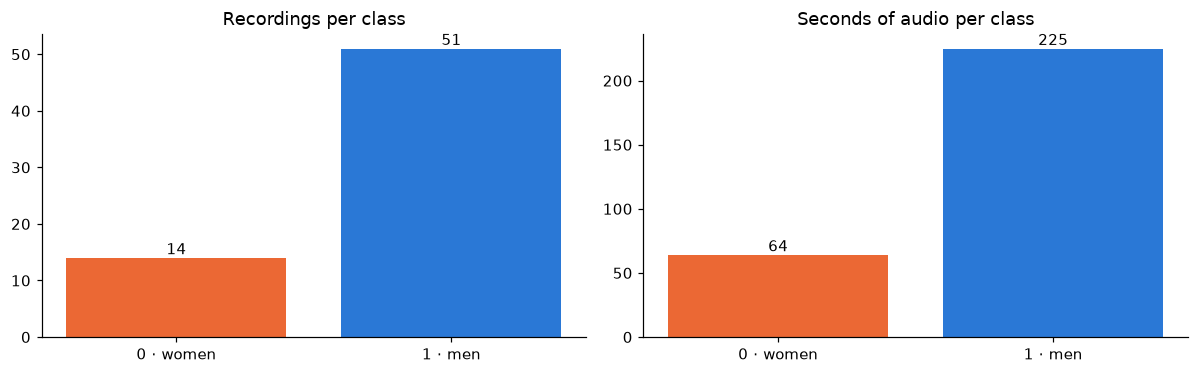

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
s = rec.groupby("class").agg(n=("file", "count"), sec=("duration_s", "sum"))
ax[0].bar([CLASS_NAME[c] for c in s.index], s.n, color=[COLORS[c] for c in s.index]); ax[0].set_title("Recordings per class")
ax[1].bar([CLASS_NAME[c] for c in s.index], s.sec, color=[COLORS[c] for c in s.index]); ax[1].set_title("Seconds of audio per class")
for a, col in zip(ax, ["n", "sec"]):
    for i, v in enumerate(s[col]): a.text(i, v, f"{v:.0f}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

### Recording length

The preprocessing cuts recordings into **3-second clips**. The dashed line marks 3 s, the dotted one 1.5 s: shorter recordings are padded with silence, and remainders under 1.5 s are dropped.

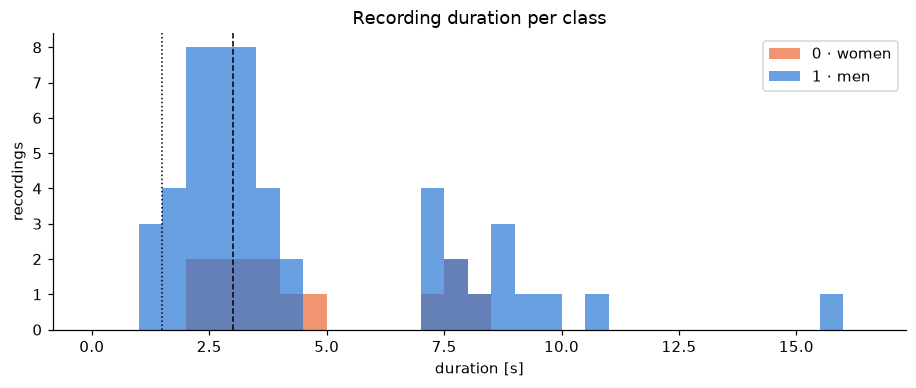

recordings shorter than 3 s: {'0 · women': 4, '1 · men': 23}


In [5]:
fig, ax = plt.subplots(figsize=(10, 3.5))
bins = np.arange(0, rec.duration_s.max() + 1, 0.5)
for c in (0, 1):
    ax.hist(rec[rec["class"] == c].duration_s, bins=bins, alpha=.7, label=CLASS_NAME[c], color=COLORS[c])
ax.axvline(3, ls="--", c="k", lw=1); ax.axvline(1.5, ls=":", c="k", lw=1)
ax.set_xlabel("duration [s]"); ax.set_ylabel("recordings"); ax.set_title("Recording duration per class"); ax.legend()
plt.show()
print("recordings shorter than 3 s:", (rec.duration_s < 3).groupby(rec["class"]).sum().rename(CLASS_NAME).to_dict())

### Sample rate

Recordings come from different devices (48 kHz and 16 kHz). The pipeline resamples everything to **16 kHz**, so the model cannot use the recording device as a shortcut.

In [6]:
pd.crosstab(rec["class"].map(CLASS_NAME), rec["sample_rate"], margins=True)

sample_rate,16000,48000,All
class,,,
0 · women,1,13,14
1 · men,10,41,51
All,11,54,65


### Speakers

In [7]:
spk = rec.groupby(["class", "speaker"]).agg(recordings=("file", "count"), seconds=("duration_s", "sum")).round(1)
spk

recordings  seconds
class speaker                       
0     Anna                2      6.5
      Iris                1      4.8
      Ulyana              2      5.8
      Yuliya              2      6.0
      unknown             3     10.3
      video10             1      7.4
      video2              1      7.8
      video4              1      7.5
      video7              1      8.0
1     Asmongold           1      7.3
      Carlos              2     11.5
      Javi                3     21.4
      Jordi               1      7.1
      Marc                1     10.6
      Victor              2     11.2
      unknown            31     88.8
      video1              1      7.4
      video11             1      7.6
      video12             1      2.6
      video13             2     12.5
      video3              1      8.9
      video5              1      8.5
      video6              1      4.5
      video8              1      7.8
      video9              1      7.4

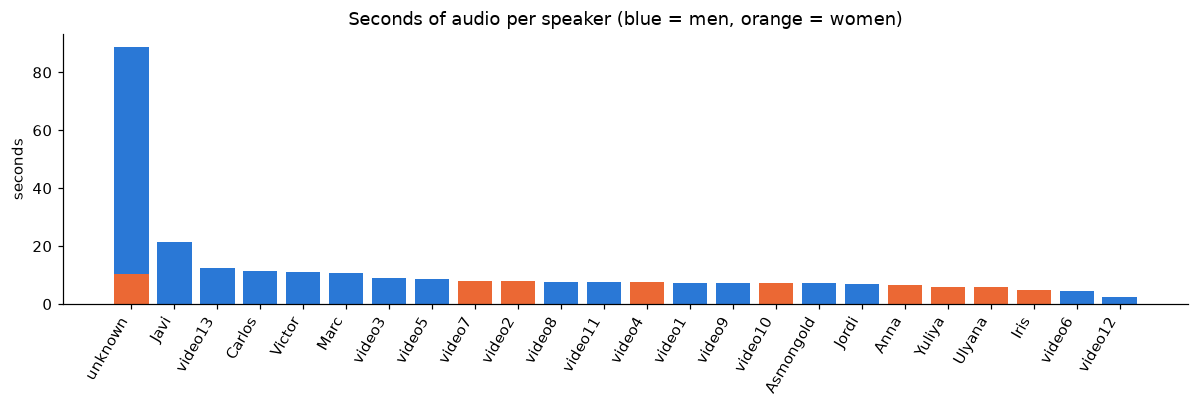

In [8]:
fig, ax = plt.subplots(figsize=(11, 3.8))
sp = rec.groupby(["speaker", "class"]).duration_s.sum().reset_index().sort_values("duration_s", ascending=False)
ax.bar(sp.speaker, sp.duration_s, color=[COLORS[c] for c in sp["class"]])
ax.set_ylabel("seconds"); ax.set_title("Seconds of audio per speaker (blue = men, orange = women)")
plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.show()

## 2. Duplicates

Two files with the same MD5 hash have identical content. Duplicates could end up in both train and test (leakage) or carry contradictory labels.

In [9]:
md5 = {f: hashlib.md5(Path(f).read_bytes()).hexdigest() for f in meta["file"]}
dup = pd.Series(md5).duplicated(keep=False)
print(f"duplicate files in data/wav: {dup.sum()}")

duplicate files in data/wav: 0


## 3. Preprocessing → clips → spectrograms

`src/preprocessing/preprocess.py`: load → mono → resample to 16 kHz → remove silence (> 30 dB below peak) → peak normalization → 3 s clips → log-mel spectrogram (64 mel bands, window 1024 = 64 ms, hop 256 = 16 ms) → `.npy`.

In [10]:
import subprocess
print(subprocess.run([sys.executable, "-m", "src.preprocessing.preprocess", "all"], capture_output=True, text=True).stdout)

clips: 74 Clips (3.0s) aus 65 Dateien -> data/clips
spectrograms: 74 .npy -> data/spectrograms (+ index.csv)



In [11]:
idx = pd.read_csv("data/spectrograms/index.csv", sep="|", dtype={"speaker_id": str})
idx["recording"] = idx["class"].astype(str) + "_" + idx["speaker_id"]
print("spectrogram shape:", np.load("data/spectrograms/" + idx.file[0]).shape, "(mel bands × time frames)")
print("clips per class:", idx["class"].map(CLASS_NAME).value_counts().to_dict())
lost = sorted(set(rec.file) - set(idx.recording))
print(f"\n{len(lost)} recordings produced no clip (shorter than 1.5 s after silence removal):")
print(lost)

spectrogram shape: (64, 188) (mel bands × time frames)
clips per class: {'1 · men': 58, '0 · women': 16}

15 recordings produced no clip (shorter than 1.5 s after silence removal):
['0_Ulyana_3', '0_unk16_1', '1_unk11_1', '1_unk12_1', '1_unk17_1', '1_unk18_1', '1_unk19_1', '1_unk21_1', '1_unk22_1', '1_unk23_1', '1_unk24_1', '1_unk35_1', '1_unk36_1', '1_unk37_1', '1_unk38_1']


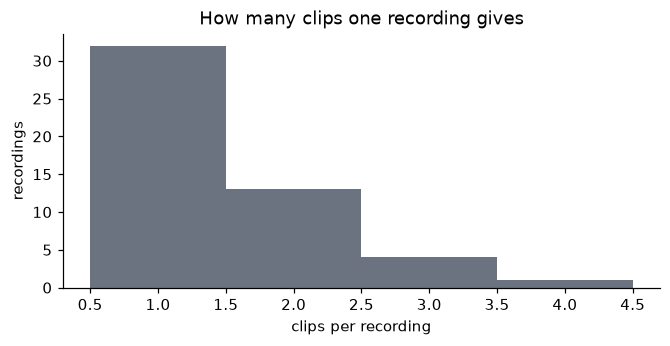

In [12]:
cpr = idx.groupby("recording").size()
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(cpr, bins=np.arange(0.5, cpr.max() + 1.5), color="#6b7280")
ax.set_xlabel("clips per recording"); ax.set_ylabel("recordings"); ax.set_title("How many clips one recording gives")
plt.show()

## 4. Spectrograms

Y axis: mel frequency (low at the bottom), X axis: time (3 s), color: energy in dB.

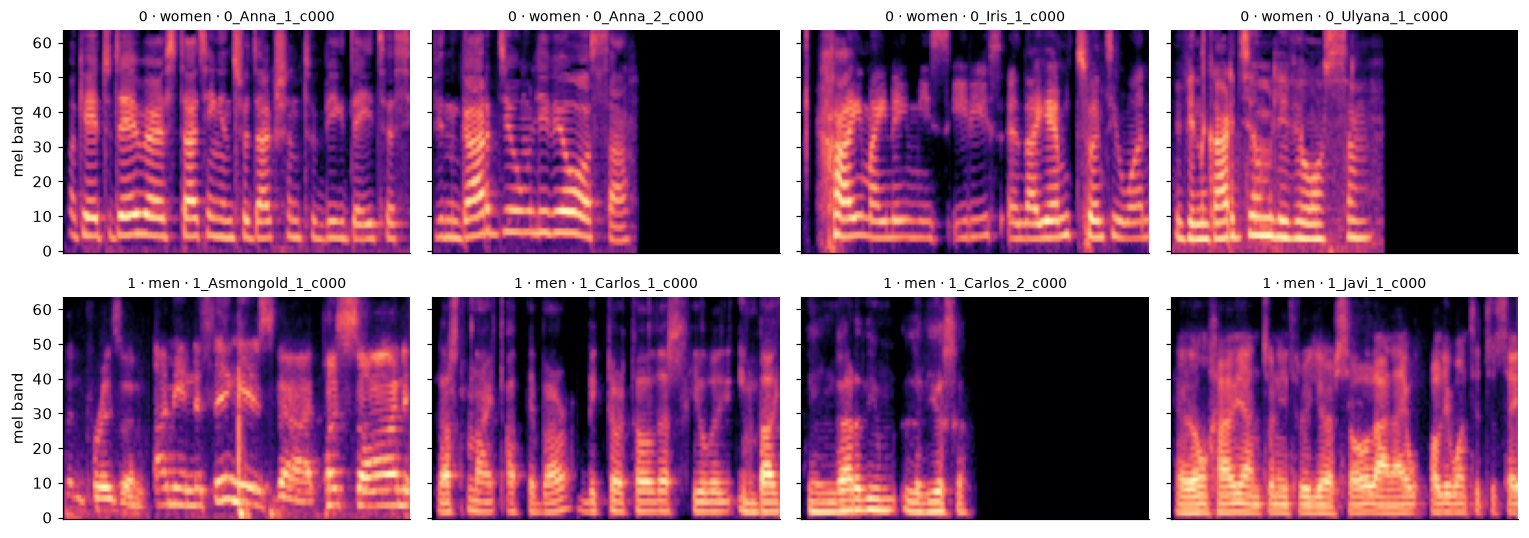

In [13]:
ex = {c: idx[(idx["class"] == c) & ~idx.speaker_id.str.startswith("unk")].groupby("speaker_id").head(1).head(4) for c in (0, 1)}
fig, axes = plt.subplots(2, 4, figsize=(14, 5), sharey=True)
for r, c in enumerate((0, 1)):
    for a, (_, row) in zip(axes[r], ex[c].iterrows()):
        a.imshow(np.load("data/spectrograms/" + row.file), origin="lower", aspect="auto", cmap="magma")
        a.set_title(f"{CLASS_NAME[c]} · {row.file[:-4]}", fontsize=9); a.set_xticks([])
    axes[r][0].set_ylabel("mel band")
plt.tight_layout(); plt.show()

### Mean spectrogram per class

Averaging all clips of a class shows where its energy typically lies. The last panel is the difference (men − women).

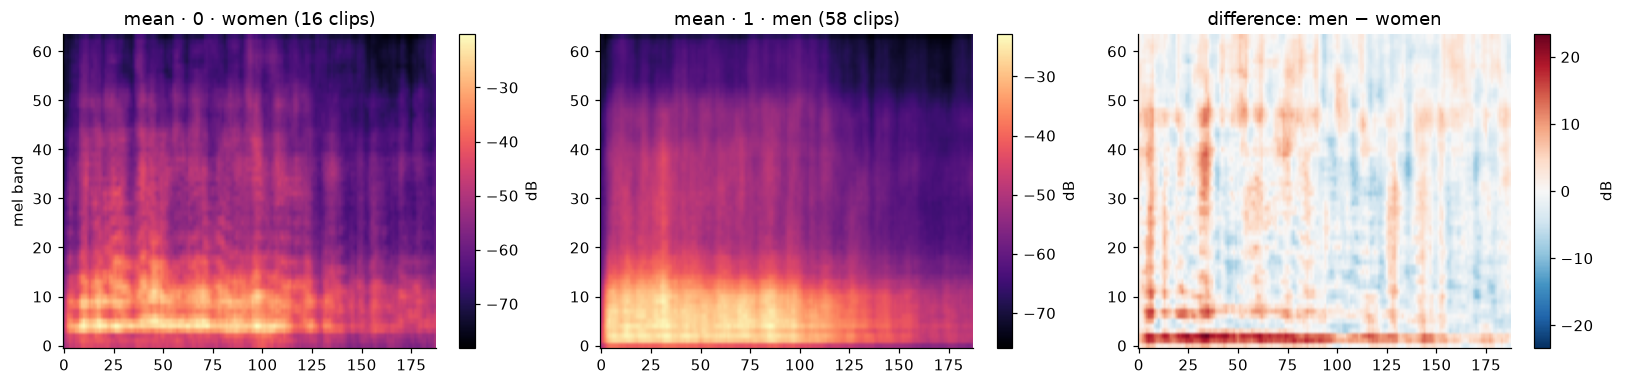

In [14]:
S = {c: np.stack([np.load("data/spectrograms/" + f) for f in idx[idx["class"] == c].file]) for c in (0, 1)}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, c in zip(ax, (0, 1)):
    im = a.imshow(S[c].mean(0), origin="lower", aspect="auto", cmap="magma"); a.set_title(f"mean · {CLASS_NAME[c]} ({len(S[c])} clips)")
    plt.colorbar(im, ax=a, label="dB")
d = S[1].mean(0) - S[0].mean(0); m = np.abs(d).max()
im = ax[2].imshow(d, origin="lower", aspect="auto", cmap="RdBu_r", vmin=-m, vmax=m); ax[2].set_title("difference: men − women")
plt.colorbar(im, ax=ax[2], label="dB"); ax[0].set_ylabel("mel band")
plt.tight_layout(); plt.show()

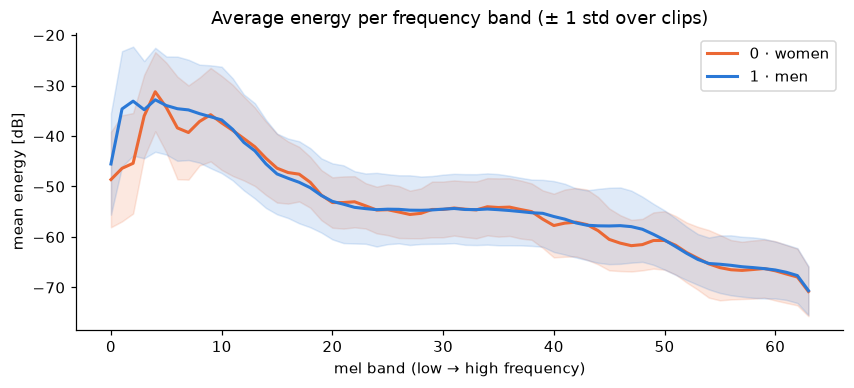

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for c in (0, 1):
    prof = S[c].mean(axis=(0, 2)); sd = S[c].mean(axis=2).std(0)
    ax.plot(prof, color=COLORS[c], lw=2, label=CLASS_NAME[c]); ax.fill_between(range(64), prof - sd, prof + sd, color=COLORS[c], alpha=.15)
ax.set_xlabel("mel band (low → high frequency)"); ax.set_ylabel("mean energy [dB]")
ax.set_title("Average energy per frequency band (± 1 std over clips)"); ax.legend(); plt.show()

## 5. Train / validation / test split

The split is made on **recordings**, not on clips: all clips of one recording go into the same part, otherwise neighbouring clips of the same recording would be in train and test (data leakage). It is stratified by class (70 / 15 / 15) with a fixed seed and saved to `data/splits/{train,val,test}.txt`.

Next step for Milestone 2: split by **speaker**, so that the same voice is never in two parts.

In [16]:
from src.model.split import get_split, PARTS
split = get_split(idx)
tab = pd.DataFrame({p: {"recordings": len(split[p]),
                        "clips": int(idx.recording.isin(split[p]).sum()),
                        "clips women (0)": int((idx.recording.isin(split[p]) & (idx["class"] == 0)).sum()),
                        "clips men (1)": int((idx.recording.isin(split[p]) & (idx["class"] == 1)).sum())} for p in PARTS}).T
tab

created new split -> data/splits


,recordings,clips,clips women (0),clips men (1)
train,34,49,11,38
val,8,10,3,7
test,8,15,2,13


In [17]:
overlap = {(a, b): len(set(split[a]) & set(split[b])) for a in PARTS for b in PARTS if a < b}
print("recordings shared between parts (must be 0):", overlap)

recordings shared between parts (must be 0): {('train', 'val'): 0, ('test', 'train'): 0, ('test', 'val'): 0}


## Summary

- 65 recordings: **51 men (class 1), 14 women (class 0)**; after preprocessing 58 vs 16 clips. The classes are strongly imbalanced (≈ 3.6 : 1) → class-weighted loss in training, and we need more female recordings.
- 35 recordings without a speaker name were labeled by listening (`unkNN`); for 3 of them (`1_unk32`–`1_unk34`) the gender is uncertain.
- Mixed devices (48 kHz / 16 kHz) → everything is resampled to 16 kHz.
- No duplicate files after cleaning.
- Many recordings are short: 15 of 65 are shorter than 1.5 s after silence removal and produce no clip at all → for Milestone 2 we need longer recordings (≥ 4 s) or padding of short ones.
- The **average** energy per frequency band is almost the same for both classes (men have slightly more energy only in the lowest bands). The average spectrum alone does not separate the classes, so the network has to use finer structure, e.g. the spacing of harmonics (pitch).
- The split is by recording and has no overlap between parts. The test set has only 2 female clips, so FAR on test is very noisy.